# Buổi F1: K-Means, chia khách thành nhóm khi chưa ai gắn nhãn

**Hiện trường.** Cửa hàng của chị Hạnh có 600 khách quen, mỗi người có hai con số: **tuổi** và **chi tiêu một tháng**. Chị muốn chia khách thành vài nhóm để gửi ưu đãi khác nhau. Không ai ghi sẵn "khách này thuộc nhóm nào". Đây là bài toán **không giám sát** (*unsupervised learning*): có dữ liệu, **không có đáp án** để chấm.

Buổi này dạy **K-Means**: chọn trước số nhóm `k`, đặt `k` điểm trung tâm, rồi lặp hai việc: *mỗi khách về trung tâm gần nhất*, *mỗi trung tâm dời về giữa nhóm của nó*, đến khi hết dịch chuyển.

**Ẩn dụ:** chia lớp thành `k` nhóm học tập. Thầy đặt `k` cái bàn ở chỗ ngẫu nhiên, ai cũng ngồi về bàn gần nhất, rồi mỗi bàn dời về giữa đám người đang ngồi quanh nó. Lặp lại cho đến khi không ai đổi bàn.

**Mindset của người làm dữ liệu:** không có đáp án thì **không có điểm đúng sai**. Nhóm tìm ra chỉ có giá trị khi **dùng được** (gửi ưu đãi khác nhau có hợp lý không). Máy luôn chia ra được `k` nhóm, kể cả khi dữ liệu không có nhóm nào.

**Lưu ý:** dữ liệu khách hàng dựng có chủ đích bằng `make_blobs` (không có bộ dữ liệu khách hàng thật nào trong sklearn); dùng để học, không dùng ra quyết định thật.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: máy chia 600 khách thành 3 nhóm |
| Chặng 1 | Tự làm K-Means bằng tay, so với sklearn |
| Chặng 2 | Chọn k: khuỷu tay và độ gọn của nhóm (silhouette) |
| Chặng 3 | Thang đo: cột nào to hơn thì cột đó lấn át |
| Chặng 4 | Hai bẫy: khởi tạo và nhóm không tròn |
| Chặng 5 | Đặt tên nhóm bằng đơn vị thật để dùng được |

## Chặng 0: Thấy ngay, máy chia 600 khách

**Câu hỏi:** nếu bảo máy "chia thành 3 nhóm", nó chia thế nào?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

           n   age  spend
cluster                  
0        200  24.7    8.1
1        203  55.3   12.1
2        197  39.4   19.6


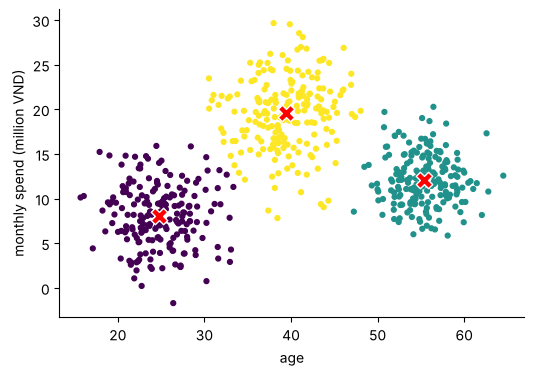

In [2]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
raw, true_group = make_blobs(n_samples=600, centers=[[25, 8], [40, 20], [55, 12]], cluster_std=[3.5, 4.0, 3.0], random_state=0)
customers = pd.DataFrame(raw, columns=["age", "spend_million"])
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(customers)
customers["cluster"] = km.labels_
print(customers.groupby("cluster").agg(n=("age", "size"), age=("age", "mean"), spend=("spend_million", "mean")).round(1).to_string())
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(customers["age"], customers["spend_million"], c=customers["cluster"], cmap="viridis", s=12)
ax.scatter(*km.cluster_centers_.T, c="red", marker="X", s=140, edgecolor="white")
ax.set_xlabel("age"); ax.set_ylabel("monthly spend (million VND)")
plt.show()

**Giải thích từng dòng**

- `make_blobs(n_samples=600, centers=[...], cluster_std=[...])`: dựng 600 điểm quanh 3 tâm cho trước. Đây là dữ liệu **dựng có chủ đích**; `true_group` ta cất đi, máy không được thấy.
- `KMeans(n_clusters=3, n_init=10, random_state=0)`: K-Means với `k = 3`. `n_init=10` là chạy 10 lần với 10 cách đặt tâm khác nhau, giữ lần tốt nhất (chặng 4 giải thích).
- `.fit(customers)`: chỉ đưa vào **dữ liệu**, không đưa nhãn. Đây là khác biệt với phân loại.
- `km.labels_`: số nhóm (0, 1, 2) máy gán cho từng khách.
- `km.cluster_centers_`: tọa độ 3 trung tâm (dấu X đỏ trên hình).

**Cách đọc.**
- **Con số:** máy chia thành ba nhóm cỡ **200, 203, 197** khách. Tuổi trung bình các nhóm: **24,7, 55,3, 39,4**.
- **Bức tranh:** ba đám điểm rõ ràng, mỗi dấu X đỏ nằm giữa một đám.
- **Câu hỏi tiếp:** máy tìm ra các tâm đó bằng cách nào? Ta tự làm một lần.

**Mang về chặng 1:** K-Means = chọn `k`, tìm `k` tâm sao cho mỗi khách gần tâm của mình.

## Chặng 1: Tự làm K-Means bằng tay

**Câu hỏi:** hai bước lặp "về bàn gần nhất, bàn dời về giữa" nghĩa là gì trong code?

In [3]:
def my_kmeans(points, k, n_iter=50, seed=0):
    rng = np.random.RandomState(seed)
    centers = points[rng.choice(len(points), k, replace=False)]
    for it in range(n_iter):
        dist = np.linalg.norm(points[:, None, :] - centers[None, :, :], axis=2)
        labels = dist.argmin(axis=1)
        new_centers = np.array([points[labels == j].mean(axis=0) for j in range(k)])
        if np.allclose(new_centers, centers):
            break
        centers = new_centers
    inertia = ((points - centers[labels]) ** 2).sum()
    return labels, centers, inertia, it + 1

pts = customers[["age", "spend_million"]].to_numpy()
my_labels, my_centers, my_inertia, my_iters = my_kmeans(pts, 3)
print("mine   : inertia", round(my_inertia, 1), "| rounds to settle:", my_iters)
print("sklearn: inertia", round(km.inertia_, 1))

mine   : inertia 14052.9 | rounds to settle: 5
sklearn: inertia 14052.9


**Giải thích từng dòng**

- `rng.choice(len(points), k, replace=False)`: chọn ngẫu nhiên `k` khách làm tâm khởi đầu.
- `np.linalg.norm(points[:, None, :] - centers[None, :, :], axis=2)`: khoảng cách từ **mỗi khách** đến **mỗi tâm**, ra bảng 600 x 3.
- `dist.argmin(axis=1)`: bước 1: mỗi khách chọn tâm có khoảng cách nhỏ nhất.
- `points[labels == j].mean(axis=0)`: bước 2: tâm mới là trung bình tọa độ của những khách đang thuộc nhóm `j`.
- `np.allclose(new_centers, centers)`: nếu tâm không dịch chuyển nữa thì dừng.
- `((points - centers[labels]) ** 2).sum()`: `inertia`: tổng bình phương khoảng cách từ mỗi khách đến tâm của mình. Càng nhỏ, nhóm càng gọn.

**Cách đọc.**
- **Con số:** bản tự viết ổn định sau **5** vòng, inertia **14052,9**; sklearn cho **14052,9**.
- **Bức tranh:** hai con số gần như trùng. K-Means chỉ là hai bước lặp, không có phép màu nào ở trong.
- **Câu hỏi tiếp:** `inertia` càng nhỏ càng tốt, vậy cứ tăng `k` mãi? Chặng 2 xét.

**Mang về chặng 2:** `inertia` đo độ gọn, mà `k` lớn thì `inertia` luôn nhỏ đi.

## Chặng 2: Chọn k bằng khuỷu tay và silhouette

**Câu hỏi:** ba nhóm có phải số đúng? Nếu không biết trước, chọn `k` thế nào?

     inertia  silhouette
k                       
2  42977.703       0.560
3  14052.946       0.647
4  11592.886       0.552
5  10094.909       0.452
6   8925.908       0.445
7   7871.333       0.320
8   6875.117       0.328


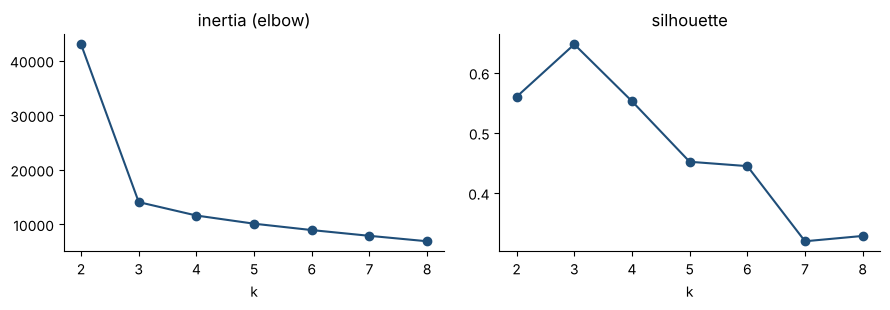

In [4]:
from sklearn.metrics import silhouette_score
ks = range(2, 9)
scan = pd.DataFrame({
    "k": list(ks),
    "inertia": [KMeans(n_clusters=k, n_init=10, random_state=0).fit(pts).inertia_ for k in ks],
    "silhouette": [silhouette_score(pts, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(pts)) for k in ks],
}).set_index("k")
print(scan.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(scan.index, scan["inertia"], "o-", color=BLUE); ax[0].set_title("inertia (elbow)"); ax[0].set_xlabel("k")
ax[1].plot(scan.index, scan["silhouette"], "o-", color=BLUE); ax[1].set_title("silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `for k in ks`: thử `k` từ 2 đến 8, mỗi lần học lại một mô hình.
- `.inertia_`: độ gọn: giảm dần khi `k` tăng, vì nhóm nhỏ hơn thì khách gần tâm hơn.
- `silhouette_score(pts, labels)`: điểm từ -1 đến 1 cho mỗi khách: gần nhóm mình hơn nhóm bên cạnh bao nhiêu. Lấy trung bình. Gần 1 là nhóm tách rõ.
- `.fit_predict(pts)`: học và trả về nhãn trong một lệnh.

**Cách đọc.**
- **Con số:** silhouette cao nhất ở **k = 3** (**0,647**). Inertia giảm từ **42978** (k=2) xuống **14053** (k=3), rồi chỉ còn giảm chậm.
- **Bức tranh:** inertia luôn giảm, nên không thể chọn `k` có inertia nhỏ nhất (khi `k` bằng số khách thì bằng 0). Ta tìm **khuỷu tay**: chỗ đường bắt đầu thoai thoải. Silhouette cho một đỉnh để so.
- **Quy tắc đọc:** hai cách chỉ là gợi ý. Nếu hai cách đồng ý như ở đây thì yên tâm hơn; nếu lệch nhau, chọn `k` theo **việc dùng nhóm** (chị Hạnh chỉ làm nổi 3 loại ưu đãi thì k = 3).
- **Câu hỏi tiếp:** K-Means dùng khoảng cách. Nếu hai cột có thang đo khác nhau thì sao?

**Mang về chặng 3:** chọn `k` bằng khuỷu tay, silhouette và mục đích dùng; không cái nào là đáp án tuyệt đối.

## Chặng 3: Thang đo, cột to lấn át cột nhỏ

**Câu hỏi:** nếu chi tiêu tính bằng **đồng** thay vì triệu đồng, kết quả có đổi không?

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
big = customers[["age", "spend_million"]].copy()
big["spend_vnd"] = big.pop("spend_million") * 1_000_000
lab_big = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(big)
lab_scaled = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(big))
print("agreement with the first result (1.0 = identical):")
print("  spend in VND, no scaling :", round(adjusted_rand_score(km.labels_, lab_big), 3))
print("  spend in VND, standardized:", round(adjusted_rand_score(km.labels_, lab_scaled), 3))
print("std of columns before scaling:", big.std().round(0).to_dict())

agreement with the first result (1.0 = identical):
  spend in VND, no scaling : 0.351
  spend in VND, standardized: 0.908
std of columns before scaling: {'age': 13.0, 'spend_vnd': 5876972.0}


**Giải thích từng dòng**

- `big.pop("spend_million") * 1_000_000`: đổi đơn vị chi tiêu từ triệu đồng sang đồng. Khách vẫn y nguyên, chỉ đổi cách viết số.
- `StandardScaler().fit_transform(big)`: đưa mỗi cột về trung bình 0, độ lệch 1, để các cột có sức nặng như nhau.
- `adjusted_rand_score(a, b)`: đo hai cách chia có giống nhau không: 1 là giống hệt, quanh 0 là như chia ngẫu nhiên.

**Cách đọc.**
- **Con số:** không chuẩn hóa, mức giống kết quả đầu chỉ còn **0,351**; chuẩn hóa xong thì về **0,908**.
- **Bức tranh:** cột chi tiêu tính bằng đồng có độ lệch hàng triệu, cột tuổi chỉ vài chục. Khoảng cách gần như chỉ nhìn vào chi tiêu, tuổi bị bỏ qua.
- **Quy tắc đọc:** với K-Means (và mọi thuật toán dùng khoảng cách), **luôn chuẩn hóa** khi các cột khác đơn vị. Đưa vào `Pipeline` như đã học ở D3.
- **Câu hỏi tiếp:** còn thuật toán nào hỏng nữa? Chặng 4.

**Mang về chặng 4:** K-Means nhạy với thang đo, chuẩn hóa trước khi gom.

## Chặng 4: Hai bẫy, khởi tạo và nhóm không tròn

**Câu hỏi:** chạy lại với tâm khởi đầu khác thì có ra kết quả khác không? Và K-Means có gom được mọi hình dạng không?

inertia over 30 single random starts: min 14052.9 | max 14052.9 | bad starts: 0
moons, agreement with the true shape (ARI): 0.269


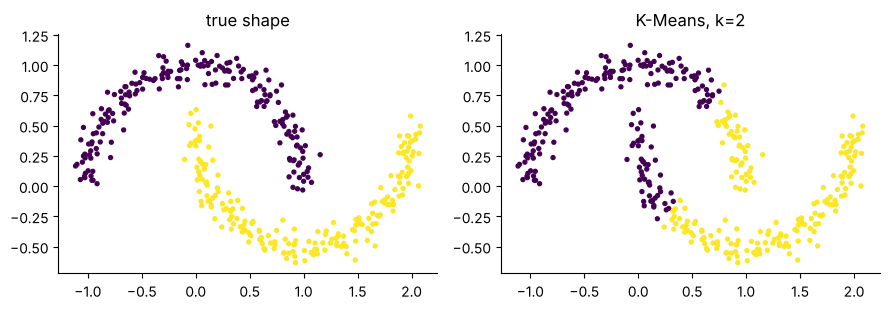

In [6]:
from sklearn.datasets import make_moons
one_start = [KMeans(n_clusters=3, n_init=1, init="random", random_state=s).fit(pts).inertia_ for s in range(30)]
print("inertia over 30 single random starts: min", round(min(one_start), 1), "| max", round(max(one_start), 1), "| bad starts:", sum(v > min(one_start) * 1.05 for v in one_start))
moons, moon_true = make_moons(400, noise=0.07, random_state=0)
moon_lab = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(moons)
print("moons, agreement with the true shape (ARI):", round(adjusted_rand_score(moon_true, moon_lab), 3))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].scatter(*moons.T, c=moon_true, s=8); ax[0].set_title("true shape")
ax[1].scatter(*moons.T, c=moon_lab, s=8); ax[1].set_title("K-Means, k=2")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `n_init=1, init="random"`: chỉ một lần đặt tâm, hoàn toàn ngẫu nhiên: đây là cách dễ gặp khởi đầu xui.
- `range(30)`: 30 hạt giống khác nhau, tức 30 cách đặt tâm khác nhau.
- `v > min(one_start) * 1.05`: đếm số lần kết quả kém hơn tốt nhất quá 5%.
- `make_moons(400, noise=0.07)`: hai hình trăng lưỡi liềm lồng nhau (dữ liệu dựng có chủ đích) để thử nhóm không tròn.

**Cách đọc.**
- **Con số:** qua 30 lần khởi đầu đơn, inertia dao động từ **14052,9** đến **14052,9**, có **0** lần xui. Với hình trăng, mức khớp hình thật chỉ **0,269**.
- **Bức tranh:** với ba đám tách rõ như ở đây, cả 30 lần khởi đầu đơn đều về cùng một kết quả, nên khởi tạo xui **không** xảy ra. Nó chỉ xuất hiện khi có nhiều nhóm hoặc các nhóm sát nhau (thử thách 1); `n_init=10` là bảo hiểm rẻ cho những lúc đó. Với hình trăng, K-Means cắt thẳng giữa chứ không đi theo đường cong, vì nó chỉ biết nhóm **hình cầu** quanh một tâm.
- **Quy tắc đọc:** K-Means hợp khi nhóm gọn, tròn, cỡ gần nhau. Không hợp với nhóm dài, cong, lồng nhau. Buổi F2 có cách khác.

**Mang về chặng 5:** giữ `n_init` lớn; kiểm tra bằng mắt xem nhóm có tròn không.

## Chặng 5: Đặt tên nhóm bằng đơn vị thật

**Câu hỏi:** chia xong, làm sao biết nhóm nào là ai để gửi ưu đãi?

In [7]:
scaler = StandardScaler().fit(pts)
final = KMeans(n_clusters=3, n_init=10, random_state=0).fit(scaler.transform(pts))
customers["segment"] = final.labels_
profile = customers.groupby("segment").agg(n=("age", "size"), mean_age=("age", "mean"), mean_spend=("spend_million", "mean")).round(1)
profile["share"] = (profile["n"] / len(customers)).round(2)
print(profile.sort_values("mean_spend").to_string())
print("agreement with the hidden true groups (ARI):", round(adjusted_rand_score(true_group, final.labels_), 3))

           n  mean_age  mean_spend  share
segment                                  
0        206      25.1         8.1   0.34
2        208      54.9        12.0   0.35
1        186      39.5        20.2   0.31
agreement with the hidden true groups (ARI): 0.903


**Giải thích từng dòng**

- `scaler.transform(pts)`: gom trên dữ liệu đã chuẩn hóa (chặng 3).
- `customers.groupby("segment").agg(...)`: tính trung bình tuổi và chi tiêu **theo đơn vị gốc** cho từng nhóm. Đây là bước biến nhóm thành "người".
- `adjusted_rand_score(true_group, final.labels_)`: vì dữ liệu dựng nên ta có đáp án ẩn để kiểm. Ngoài đời không có bước này.

**Cách đọc.**
- **Con số:** ba nhóm có chi tiêu trung bình **8,1, 12,0, 20,2** triệu, tuổi trung bình **25,1, 54,9, 39,5**. Khớp với nhóm ẩn: **0,903**.
- **Bức tranh:** đặt tên theo hồ sơ (ví dụ "trẻ chi ít", "trung niên chi nhiều") rồi hỏi chị Hạnh có gửi ưu đãi khác nhau được không. Nhóm không đặt được tên thì thường chưa hữu ích.
- **Lưu ý:** ngoài đời không có nhóm ẩn để chấm. Điểm tin cậy nhất là nhóm **ổn định** (chia lại bằng mẫu khác vẫn ra nhóm tương tự) và **dùng được**.

**Mang về:** gom → đọc hồ sơ nhóm bằng đơn vị gốc → đặt tên → hỏi có hành động khác nhau được không.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Học không giám sát: có dữ liệu, không có nhãn; máy luôn chia được k nhóm. |
| 1 | K-Means = hai bước lặp: về tâm gần nhất, tâm dời về giữa. |
| 2 | Chọn k bằng khuỷu tay, silhouette và mục đích dùng. |
| 3 | Chuẩn hóa trước khi gom; cột to lấn cột nhỏ. |
| 4 | Giữ n_init như bảo hiểm; K-Means chỉ gom tốt nhóm tròn. |
| 5 | Đặt tên nhóm bằng đơn vị gốc; giá trị nằm ở việc dùng được. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Chia lớp thành các nhóm học | gom nhóm | `KMeans` |
| Số bàn thầy đặt | số nhóm | `n_clusters` |
| Cái bàn | tâm nhóm | `cluster_centers_` |
| Tổng khoảng cách đến bàn | độ gọn nhóm | `inertia_` |
| Thử nhiều cách đặt bàn | nhiều lần khởi tạo | `n_init` |
| Ai ngồi gần bàn mình hơn bàn bên cạnh | hệ số silhouette | `silhouette_score` |
| Hai cách chia có giống nhau | chỉ số Rand điều chỉnh | `adjusted_rand_score` |

**Thử thách tự làm**

1. Ở chặng 2, thêm 4 nhóm khách nữa vào `make_blobs` (tổng 7 tâm). Khuỷu tay và silhouette còn cho cùng một `k` không?
2. Chạy chặng 3 với cột thứ ba là `visits_per_month` (ít hơn 30). Có cần chuẩn hóa không? Vì sao?
3. Thay `KMeans` bằng `MiniBatchKMeans`. Kết quả và thời gian khác bao nhiêu trên 100.000 khách?
4. Chạy chặng 1 với `seed` từ 0 đến 9. Số vòng ổn định có đổi không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích hai bước lặp của K-Means.
- [ ] Chọn k có lý do, không đoán.
- [ ] Biết khi nào phải chuẩn hóa.
- [ ] Nhận ra nhóm không tròn thì K-Means không hợp.
- [ ] Đặt tên nhóm bằng đơn vị gốc.

## Phần thưởng (Tip pro): MiniBatchKMeans cho dữ liệu cực lớn


Khi có hàng triệu khách, K-Means chuẩn chậm. `MiniBatchKMeans` mỗi vòng chỉ nhìn một mẻ nhỏ ngẫu nhiên để cập nhật tâm: nhanh hơn nhiều, đổi lại nhóm kém gọn một chút. Đó là cùng ý với "mini-batch" mà ta sẽ gặp ở học sâu.